<a href="https://colab.research.google.com/github/ntienvo/ML-lab/blob/main/Lab06_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 06 – Linear Regression with California Housing

## Learning objectives

By the end of this lab, students will be able to:

1. Explore and visualize a real-world regression dataset.
2. Build and interpret a simple linear regression model.
3. Extend the model to multiple linear regression.
4. Implement batch gradient descent using NumPy.
5. Evaluate regression models using MAE, MSE, RMSE, and R².
6. Train and evaluate linear regression models using Scikit-learn.

## Dataset

We use the **California Housing** dataset available through `sklearn.datasets.fetch_california_housing`.

Each observation represents a California census block group, not an individual house. The target, `MedHouseVal`, is the median house value expressed in units of $100,000. The target is capped at 5.0, so values at the upper boundary should be interpreted with care.

The dataset contains eight input features:
- `MedInc`: median income
- `HouseAge`: median house age
- `AveRooms`: average rooms
- `AveBedrms`: average bedrooms
- `Population`: block-group population
- `AveOccup`: average household occupancy
- `Latitude`: geographic latitude
- `Longitude`: geographic longitude


## Part 0 – Setup

Import the libraries required for this lab. We will use NumPy for numerical operations, Pandas for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for data splitting, preprocessing, and model training.

In [10]:
# TODO:
# 1. Import numpy as np and pandas as pd.
# 2. Import matplotlib.pyplot as plt and seaborn as sns.
# 3. Import fetch_california_housing and train_test_split.
# 4. Import StandardScaler, LinearRegression, and regression metrics.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

## Part A – Dataset Loading and Exploration

### A1. Load the dataset

Load the California Housing dataset as a Pandas DataFrame. Separate the input features (`X`) from the target (`y`).

In [11]:
# TODO:
# Load the dataset with as_frame=True.
# Create X from the feature columns and y from the target.
# Display the first five rows of X and y.

housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

display(X.head())
display(y.head())


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


### A2. Inspect the dataset

Check the dataset dimensions, feature names, data types, missing values, and descriptive statistics.

In [12]:
# TODO:
# Print the shape of X and y.
# Display X.info(), X.describe(), and the number of missing values per column.

display(f"Shape of X: {X.shape}")
display(f"Shape of y: {y.shape}")

X.info()
display(X.describe())

display(X.isnull().sum())


'Shape of X: (20640, 8)'

'Shape of y: (20640,)'

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


### A3. Understand the target variable

Plot the distribution of `MedHouseVal`. What do you notice about the upper end of the distribution?

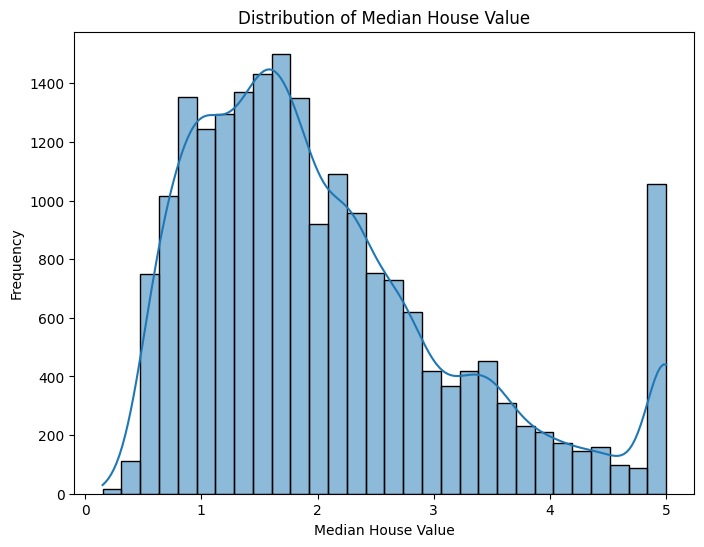

In [ ]:
# TODO:
# Plot a histogram of y with an appropriate number of bins.
# Add a title and axis labels.
plt.figure(figsize = (8,6))
sns.histplot(y, bins = 30, kde = 2)
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

**Question A3:** Why should we be cautious when interpreting predictions near the maximum target value of 5.0?

### A4. Explore feature relationships

Create a correlation heatmap for the eight input features and the target. Identify at least two variables that appear to have a relationship with `MedHouseVal`.

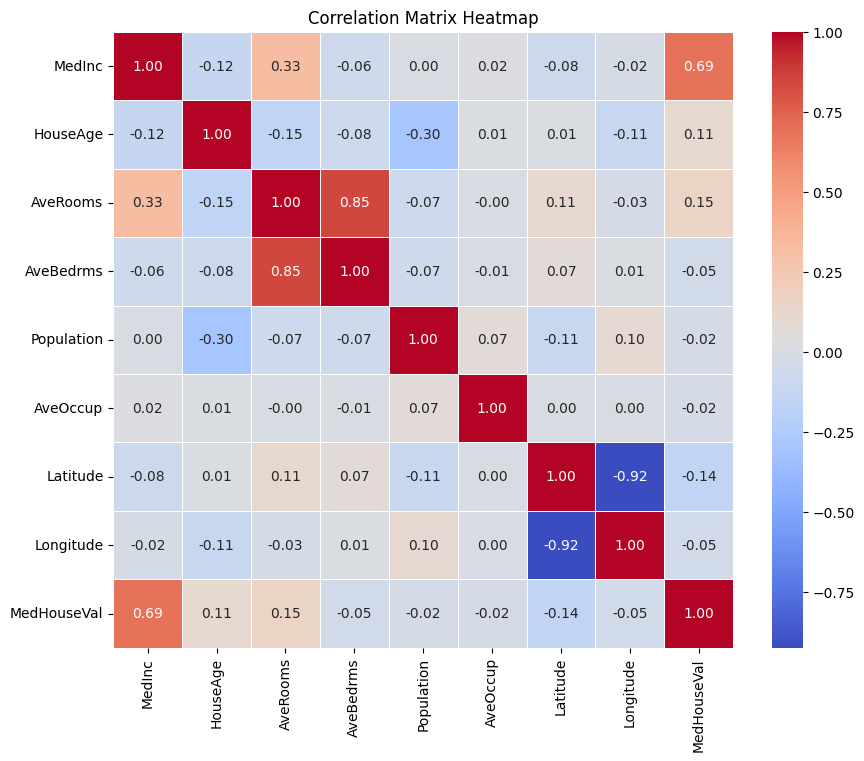

In [13]:
# TODO:
# Combine X and y into one DataFrame.
# Compute the correlation matrix and draw a heatmap.

full_df = pd.concat([X, y], axis=1)
corr_matrix = full_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

### A5. Split the data

Split the dataset into training and testing sets. Use 80% for training and 20% for testing. Set `random_state=42` so that results are reproducible.

**Rule:** Any preprocessing operation that learns parameters from data must be fitted using the training set only.

In [14]:
# TODO:
# Use train_test_split to create X_train, X_test, y_train, and y_test.
# Print the resulting shapes.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test (4128,)


## Part B – Simple Linear Regression

In this part, we use only one input feature: `MedInc` (median income), to predict `MedHouseVal`.

The simple linear regression model is:

$$
\hat{y} = w x + b
$$

where:
- $x$ is the median income,
- $w$ is the slope,
- $b$ is the intercept,
- $\hat{y}$ is the predicted median house value.

### B1. Select one feature

Create one-dimensional feature matrices for training and testing. Scikit-learn expects a two-dimensional input array.

In [21]:
# TODO:
# Select the MedInc column from X_train and X_test.
# Use double square brackets so that each result remains 2D.
X_train_model = X_train[["MedInc"]]
X_test_model = X_test[["MedInc"]]
print(X_train_model.shape, X_test_model.shape)

(16512, 1) (4128, 1)


### B2. Fit a simple linear regression model

Train a `LinearRegression` model using the training data. Display its slope (`coef_`) and intercept (`intercept_`).

In [22]:
# TODO:
# Create a LinearRegression object.
# Fit it using X_train_simple and y_train.
# Print the learned coefficient and intercept.

# Create a LinearRegression object.
simple_model = LinearRegression()

# Fit it using X_train_simple and y_train.
simple_model.fit(X_train_model, y_train)

# Print the learned coefficient and intercept.

print(f"Learned Coefficient (w / slope): {simple_model.coef_[0]:.4f}")
print(f"Learned Intercept (b): {simple_model.intercept_:.4f}")
print(f"Mô hình tìm được: ŷ = {w:.4f} * x + {b:.4f}")


Learned Coefficient (w / slope): 0.4193
Learned Intercept (b): 0.4446


NameError: name 'w' is not defined

### B3. Visualize the regression line

Draw a scatter plot of the training data and overlay the fitted regression line. Sort the x-values before drawing the line so that the line is displayed correctly.

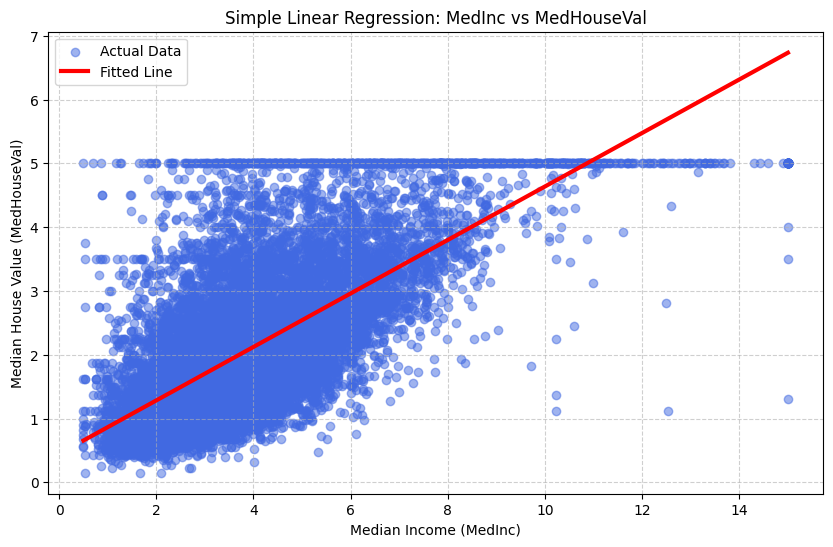

In [23]:
# TODO:
# Predict using X_train_simple.
# Sort MedInc values and their corresponding predictions.
# Draw the scatter plot and fitted line.

y_train_pred = simple_model.predict(X_train_model)

X_vals = X_train_model["MedInc"].values
y_preds = y_train_pred

sort_idx = np.argsort(X_vals)
X_vals_sorted = X_vals[sort_idx]
y_preds_sorted = y_preds[sort_idx]

plt.figure(figsize=(10, 6))
plt.scatter(X_train_model, y_train, alpha=0.5, color="royalblue", label="Actual Data")
plt.plot(X_vals_sorted, y_preds_sorted, color="red", linewidth=3, label="Fitted Line")

plt.xlabel("Median Income (MedInc)")
plt.ylabel("Median House Value (MedHouseVal)")
plt.title("Simple Linear Regression: MedInc vs MedHouseVal")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


### B4. Make predictions

Use the trained model to predict median house values for the test set. Display the first ten actual and predicted values side by side.

In [ ]:
# Predict y for X_test_simple.
y_test_pred = simple_model.predict(X_test_simple)

simple_result = pd.DataFrame({"Actual": y_test.to_numpy(),
                             "Predicted": y_test_pred})
display(simple_result.head(10))

,Actual,Predicted
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


In [ ]:
# TODO:
# Predict y for X_test_simple.
# Create a DataFrame with actual and predicted values.
# Display the first ten rows.

y_test_pred = simple_model.predict(X_test_simple)

# Create a DataFrame with actual and predicted values.
comparison_df = pd.DataFrame({
    "Actual Value (y_test)": y_test,
    "Predicted Value (y_pred)": y_test_pred
})

# Reset lại chỉ mục (index) từ 0 để bảng hiển thị gọn gàng, dễ nhìn hơn
comparison_df = comparison_df.reset_index(drop=True)

# Display the first ten rows.
display(comparison_df.head(10))


,Actual Value (y_test),Predicted Value (y_pred)
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


**Questions – Part B**

1. Is the relationship between median income and median house value perfectly linear?
2. What does a positive slope mean in this model?
3. What information is ignored when only `MedInc` is used?

## Part C – Closed-Form Solution: Normal Equation

In Part B, we used Scikit-learn to estimate the slope and intercept of a simple linear regression model. In this part, we calculate these parameters directly using the **Normal Equation**.

For simple linear regression, the model is:

$$
\hat{y}^{(i)} = wx^{(i)} + b
$$

To express the model in matrix form, we add a column of ones to the input feature matrix. This allows the intercept $b$ to be included in the parameter vector.

Let the augmented design matrix and parameter vector be:

$$
\mathbf{X}_{aug} =
\begin{bmatrix}
1 & x^{(1)} \\
1 & x^{(2)} \\
\vdots & \vdots \\
1 & x^{(n)}
\end{bmatrix},
\qquad
\boldsymbol{\theta} =
\begin{bmatrix}
b \\ w
\end{bmatrix}
$$

The Normal Equation is:

$$
\boldsymbol{\theta}^{*}
=
(\mathbf{X}_{aug}^{T}\mathbf{X}_{aug})^{-1}
\mathbf{X}_{aug}^{T}\mathbf{y}
$$

Here, the first element of $\boldsymbol{\theta}^{*}$ is the intercept $b$, and the second element is the slope $w$.

In the implementation, use `np.linalg.solve()` instead of explicitly calculating the matrix inverse. It solves the equivalent linear system and is generally more numerically stable.

In [24]:
# TODO:
# 1. Convert the MedInc training feature into a NumPy array.
# 2. Construct X_aug with a column of ones as the FIRST column.
# 3. Compute theta using np.linalg.solve().
# 4. Extract and print the slope and intercept.
x_train_values = X_train_model["MedInc"].to_numpy(dtype=np.float64)
y_train_values = y_train.to_numpy(dtype=np.float64)
X_aug = np.column_stack((np.ones_like(x_train_values),x_train_values))

A = X_aug.T @ X_aug
b = X_aug.T @ y_train_values
theta = np.linalg.inv(A) @ (b)

intercept = theta[0]
slope = theta[1]

print(f"Manual Intercept (b): {intercept:.4f}")
print(f"Manual Slope (w / coefficient): {slope:.4f}")

Manual Intercept (b): 0.4446
Manual Slope (w / coefficient): 0.4193


In [25]:
x_train_values = X_train_model["MedInc"].to_numpy(dtype=np.float64)
y_train_values = y_train.to_numpy(dtype=np.float64)
X_aug = np.column_stack((np.ones_like(x_train_values),x_train_values))

A = X_aug.T @ X_aug
b = X_aug.T @ y_train_values
theta = np.linalg.solve(A, b) # SOLVE tot hon INV

intercept = theta[0]
slope = theta[1]

print(f"Manual Intercept (b): {intercept:.4f}")
print(f"Manual Slope (w / coefficient): {slope:.4f}")

Manual Intercept (b): 0.4446
Manual Slope (w / coefficient): 0.4193


### C2. Compare the Normal Equation with Scikit-learn

Compare the slope and intercept obtained from the Normal Equation with the parameters learned by `simple_model` in Part B. Also calculate the absolute difference between the two methods.

In [ ]:
# Compare the Normal Equation parameters with:
# simple_model.coef_[0] and simple_model.intercept_.
# (Giả định biến từ sklearn của bạn tên là model_simple và biến từ Numpy là slope, intercept)
comparison = pd.DataFrame({
    "Normal Equation": [slope, intercept],
    "Scikit-learn": [simple_model.coef_[0], simple_model.intercept_]
}, index=["Slope (w)", "Intercept (b)"])

# Display both sets of parameters and their absolute differences.
comparison["Absolute Difference"] = (comparison["Normal Equation"] - comparison["Scikit-learn"]).abs()

display(comparison)



,Normal Equation,Scikit-learn,Absolute Difference
Slope (w),0.419338,0.419338,9.603429e-15
Intercept (b),0.444597,0.444597,3.980150e-14


**Questions – Part C**

1. Are the slope and intercept from the Normal Equation close to those from Scikit-learn?
2. Why do the two approaches produce nearly identical parameters?
3. Why is `np.linalg.solve()` preferred to explicitly computing the inverse?
4. What could happen if the matrix being inverted is singular or nearly singular?

## Part D – Multiple Linear Regression

Simple linear regression uses one feature. Multiple linear regression uses several features:

$$
\hat{y} = w_1x_1 + w_2x_2 + \cdots + w_dx_d + b
$$

Here, all eight California Housing features are used to predict `MedHouseVal`.

### C1. Train a multiple linear regression model

Fit a linear regression model using all eight features. Display the intercept and the coefficient associated with each feature.

In [ ]:
# TODO:
# Create and fit a LinearRegression model using X_train and y_train.
# Display the intercept and coefficients in a Pandas Series.
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

print(f"Intercept b: {multiple_model.intercept_:.3f}")

Intercept b: -37.023


### C2. Interpret the coefficients

A coefficient represents the expected change in the prediction for a one-unit increase in that feature, **holding the other features constant**.

Coefficient magnitudes should not be compared naively when features use different units or scales.

**Questions – Part D**

1. Which feature has the largest positive coefficient?
2. Which feature has the largest negative coefficient?
3. Why does the interpretation “holding the other features constant” matter?
4. Why might coefficient magnitude be difficult to compare across features in this dataset?

## Part E – Gradient Descent from Scratch

In this part, you will implement batch gradient descent using NumPy for multiple linear regression.

The objective is to minimize the mean squared error:

$$
J(\mathbf{w}, b) = \frac{1}{m}\sum_{i=1}^{m}
(\hat{y}^{(i)} - y^{(i)})^2
$$

For numerical stability and easier optimization, standardize the input features. The scaler must be fitted on the training set only.

### D1. Standardize the features

Use `StandardScaler`. Fit it on `X_train`, then transform both the training and testing sets.

In [35]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to numpy arrays explicitly
X_train_np = np.asarray(X_train_scaled, dtype=np.float64)
X_test_np = np.asarray(X_test_scaled, dtype=np.float64)

print("Scaled training shpape:", X_train_np.shape)
print("Scaled testing shpape:", X_test_np.shape)

Scaled training shpape: (16512, 8)
Scaled testing shpape: (4128, 8)


### D2. Define the prediction and loss functions

For a batch of samples, use:

$$
\hat{\mathbf{y}} = \mathbf{X}\mathbf{w} + b
$$

Implement:
- `predict(X, w, b)`: returns predictions.
- `compute_mse(y_pred, y)`: returns mean squared error.

In [ ]:
# TODO:
# Implement predict() and compute_mse().


In [53]:
def predict(X, w, b):
    # X is shape (m, d), w is shape (d,),
    # y_pred = X @ w + b (shape (m,))
    return X @ w + b

def compute_mse(y_pred, y):
    # Return mean squared error
    return np.mean((y_pred - y) ** 2)

def compute_cost(y_pred, y):
    # Use our correct compute_mse function to avoid the np.mean() argument error
    return 0.5 * compute_mse(y_pred, y)

### D3. Derive the gradients

For each training example, the prediction is:

$$
\hat{y}^{(i)} = w_1x_1^{(i)} + w_2x_2^{(i)} + \cdots + w_dx_d^{(i)} + b
$$

Let $n$ be the number of training examples. We define the cost function as:

$$
J(\mathbf{w}, b) = \frac{1}{2}\sum_{i=1}^{n}
(\hat{y}^{(i)} - y^{(i)})^2
$$

The gradient with respect to each weight $w_j$ is:

$$
\frac{\partial J}{\partial w_j}
= \sum_{i=1}^{n}
(\hat{y}^{(i)} - y^{(i)})x_j^{(i)}
$$

The gradient with respect to the bias $b$ is:

$$
\frac{\partial J}{\partial b}
= \sum_{i=1}^{n}(\hat{y}^{(i)} - y^{(i)})
$$

The update rules are:

$$
w_j := w_j - \alpha \frac{\partial J}{\partial w_j},
\qquad
b := b - \alpha \frac{\partial J}{\partial b}
$$

Since this objective uses a sum rather than an average, the gradient magnitude depends on the number of training examples. Therefore, a much smaller learning rate is required.

Implement one gradient descent update. The function should return the updated weights and bias.

In [ ]:
# TODO:
# Implement gradient_descent_step(X, y, w, b, learning_rate).
# Compute predictions, errors, gradients, and update w and b.

In [49]:
def gradient_descent_step(X, y, w, b, learning_rate):
    y_predict = predict(X, w, b)
    error = y_predict - y

    d_w = X.T @ error
    w = w - learning_rate * d_w

    db = np.sum(error)
    b = b - learning_rate * db

    return w, b

### D4. Train using batch gradient descent

Initialize weights and bias to zero. Train for 1,000 iterations with a learning rate of 0.05. Record the training loss at each iteration.

In [ ]:
# TODO:
# Initialize w as a zero vector and b as 0.0.
# Run 1000 gradient descent iterations.
# Store the MSE after each update in a list named loss_history.

In [54]:
n_interations = 1000
w = np.zeros(X_train_scaled.shape[1], dtype = np.float64)
b = 0.0
loss_history = []

# Because your gradient_descent_step calculates the gradient using sums (without dividing by m),
# we need a tiny learning rate (like 0.00005) so it doesn't diverge.
learning_rate = 0.00005

for i in range(n_interations):
    w, b = gradient_descent_step(X_train_np, y_train.to_numpy(), w, b, learning_rate)
    y_predict = predict(X_train_np, w, b)
    current_loss = compute_cost(y_predict, y_train.to_numpy())
    loss_history.append(current_loss)

print(f"Final Loss: {current_loss:.3f}")
print(f"Final Weights: {w}")
print(f"Final Bias: {b}")

Final Loss: 0.259
Final Weights: [ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291
 -0.89692888 -0.86984178]
Final Bias: 2.071946937378881


### D5. Visualize the learning curve

Plot the training loss against the iteration number. A decreasing curve indicates that the optimization is making progress.

In [ ]:
# TODO:
# Plot loss_history.
# Add axis labels and a title.

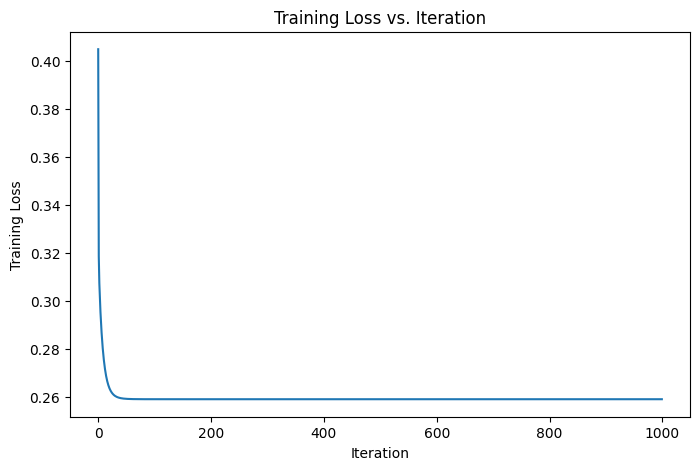

In [56]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history, label="Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.title("Training Loss vs. Iteration")
plt.show()

### D6. Experiment with the learning rate

Repeat training with at least two different learning rates, for example `0.005` and `0.2`. Compare the loss curves and final training losses.

If a learning rate is too large, optimization may become unstable or diverge.

In [ ]:
# TODO:
# Write a small training loop or helper function that trains the model
# for a supplied learning rate and returns its loss history.
# Compare learning rates 0.005, 0.05, and 0.2.

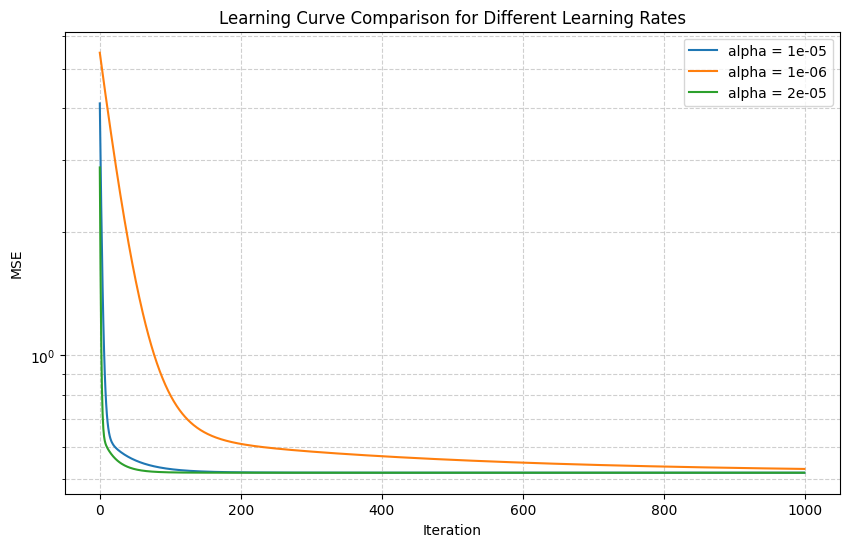

In [58]:
def train_gradient_descent(X, y, learning_rate, num_iterations=1000):
    num_features = X.shape[1]
    w = np.zeros(num_features)
    b = 0.0
    history = []
    for _ in range(num_iterations):
        w, b = gradient_descent_step(X, y, w, b, learning_rate)
        loss = compute_mse(predict(X, w, b), y)
        history.append(loss)
    return history, w, b

lr_list = [1e-5, 1e-6, 2e-5]
plt.figure(figsize=(10, 6))

for lr in lr_list:
    history, _, _ = train_gradient_descent(X_train_scaled, y_train.to_numpy(), lr)
    plt.plot(history, label=f"alpha = {lr}")

plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("Learning Curve Comparison for Different Learning Rates")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.show()

### D7. Evaluate the from-scratch model on the test set

Use the final weights and bias learned in D4 to make predictions on the scaled test set. Compute the test MSE.

In [ ]:
# TODO:
# Predict on X_test_np using w and b.
# Compute and print the test MSE.

In [67]:
# We will use the weights and bias learned in D4 (trained with learning_rate=0.05)
y_test_gd_pred = predict(X_test_np, w, b)
test_mse_gd = compute_mse(y_test_gd_pred, y_test.to_numpy())
print(f"Test MSE (Gradient Descent):",test_mse_gd)

Test MSE (Gradient Descent): 0.5558915986952442


**Questions – Part E**

1. Why do we standardize the input features before gradient descent?
2. Why must the scaler be fitted only on the training set?
3. What happens when the learning rate is too small? What can happen when it is too large?
4. Why do we use the average squared error rather than the sum of squared errors?

## Part F – Model Evaluation

We evaluate regression models using four common metrics.

- **MAE:** average absolute prediction error.
- **MSE:** average squared prediction error; larger errors receive a larger penalty.
- **RMSE:** square root of MSE, expressed in the same unit as the target.
- **R²:** proportion of target variance explained by the model relative to predicting the test-set mean.

For this dataset, the target is measured in units of $100,000. Therefore, an RMSE of 0.5 corresponds to approximately $50,000.

### E1. Implement a reusable evaluation function

Complete a function that calculates MAE, MSE, RMSE, and R².

In [61]:
def evaluate_regression(y_true, y_pred):
    # Calculate regression metrics
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    # Return a dictionary containing all metrics
    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

### E2. Evaluate simple and multiple linear regression

Calculate all four metrics on the test set for both models. Present the results in a DataFrame.

In [69]:
y_test_multiple_pred = multiple_model.predict(X_test)
y_test_simple_pred = simple_model.predict(X_test_model)

simple_metrics = evaluate_regression(y_test, y_test_simple_pred)
multiple_metrics = evaluate_regression(y_test, y_test_multiple_pred)

metrics_df = pd.DataFrame(
    [simple_metrics, multiple_metrics],
    index=["Simple Linear Regression", "Multiple Linear Regression"]
)
display(metrics_df)

,MAE,MSE,RMSE,R2
Simple Linear Regression,0.629909,0.709116,0.842090,0.458859
Multiple Linear Regression,0.533200,0.555892,0.745581,0.575788


### E3. Visualize actual versus predicted values

For the multiple linear regression model, create a scatter plot of actual values against predicted values. Add a diagonal reference line. Predictions close to this line are more accurate.

In [ ]:
# TODO:
# Create an actual-versus-predicted scatter plot.
# Draw a y=x reference line using the minimum and maximum values.

### E4. Inspect prediction errors

Calculate residuals as:

$$
e^{(i)} = y^{(i)} - \hat{y}^{(i)}
$$

Plot the residual distribution. A residual is positive when the model underpredicts and negative when it overpredicts.

In [ ]:
# TODO:
# Calculate residuals for the multiple linear regression model.
# Plot their histogram and add a vertical line at zero.

**Questions – Part F**

1. Which metric is easiest to interpret in the target's original unit? Why?
2. Why does MSE penalize large errors more strongly than MAE?
3. What does a negative R² indicate?
4. Does a high R² guarantee that every prediction is accurate?

## Part G – Scikit-learn Workflow

In this part, summarize the standard workflow for building a regression model with Scikit-learn. The model has already been trained in Part D; now use the familiar `fit`, `predict`, and `score` methods explicitly.

In [ ]:
# TODO:
# Fit a new LinearRegression model on the training set.
# Predict the test set.
# Print the model's R² score and compare it with r2_score().

### F2. Predict for a single example

Select one row from the test set. Display its feature values, the model prediction, and the actual target value.

In [ ]:
# TODO:
# Select the first test example as a one-row DataFrame.
# Predict its target and print the actual and predicted values.